In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

events = pd.read_csv('data/events.csv')
listings = pd.read_csv('data/listings.csv')
messages = pd.read_csv('data/messages.csv')
surveys = pd.read_csv('data/surveys.csv')
verified = pd.read_csv('data/verified.csv')

verified_0 = verified[verified['is_deal'] == 0]
verified_1 = verified[verified['is_deal'] == 1]

verified_0, verified_1

(     listing_id  is_deal
 0        100681        0
 1        101419        0
 2        101514        0
 3        101847        0
 4        101907        0
 ..          ...      ...
 292      160017        0
 294      160585        0
 296      160740        0
 297      161072        0
 299      161231        0
 
 [184 rows x 2 columns],
      listing_id  is_deal
 5        102003        1
 6        102331        1
 9        102885        1
 10       103007        1
 11       103373        1
 ..          ...      ...
 282      158309        1
 288      159086        1
 293      160166        1
 295      160714        1
 298      161213        1
 
 [116 rows x 2 columns])

## Относительная цена проверенных объявлений

In [ ]:
relative_prices = pd.read_csv(
    "data_by_dewallen/features.csv",
    usecols=["listing_id", "relative_price"],
    float_precision="round_trip",
)
listing_details = listings.drop_duplicates().astype({"description_length": "Int64"})

verified_relative_price = verified[["listing_id", "is_deal"]].merge(
    relative_prices, on="listing_id", how="left", validate="one_to_one",
)
verified_relative_price = verified_relative_price.merge(
    listing_details, on="listing_id", how="left", validate="one_to_one",
)

output_path = "data_by_dewallen/verified_relative_price.csv"
verified_relative_price.to_csv(output_path, index=False)
print(f"Сохранено {len(verified_relative_price)} строк в {output_path}")
print("Строк без relative_price:", verified_relative_price["relative_price"].isna().sum())
verified_relative_price.head()

In [2]:
verified_listings_0 = listings[listings['listing_id'].isin(verified_0['listing_id'])].drop_duplicates(subset=['listing_id'])
verified_listings_1 = listings[listings['listing_id'].isin(verified_1['listing_id'])].drop_duplicates(subset=['listing_id'])

verified_listings_0

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
96,152219,38883,private,Спорт и отдых,Коньки отличное состояние,5260,5260,2,45.0,Краснодар,2026-09-27 18:03:35,2026-10-03 13:31:14,снято продавцом,36,0,0,3,6
162,133335,26727,private,Бытовая техника,Мультиварка торг,19120,19120,4,61.0,Москва,2026-09-09 08:22:14,2026-09-14 12:56:15,снято продавцом,60,3,0,1,13
242,115714,22840,private,Мебель и интерьер,Люстра,9300,7550,4,129.0,Москва,2026-08-19 21:24:55,2026-09-18 21:24:55,истёк срок,278,7,3,11,42
287,159583,19213,private,Электроника,Игровая приставка,14770,14770,2,NaN,Екатеринбург,2026-10-04 17:49:59,2026-10-18 20:38:31,снято продавцом,146,6,2,4,13
294,109228,18276,private,Детские товары,Комбинезон зимний,5250,3980,3,176.0,Москва,2026-08-12 15:53:29,2026-09-11 15:53:29,истёк срок,169,4,2,13,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15125,114464,12962,private,Электроника,iPhone 12 128 ГБ б/у,14470,14470,5,122.0,Краснодар,2026-08-18 15:28:05,2026-09-17 15:28:05,истёк срок,294,12,3,14,53
15148,125458,20955,private,Мебель и интерьер,Люстра,4110,4110,3,50.0,Москва,2026-08-31 20:19:52,2026-09-09 13:56:03,снято продавцом,53,2,0,2,5
15161,122935,21280,private,Одежда и обувь,Свитер вязаный в хорошем состоянии,2170,2170,4,100.0,Краснодар,2026-08-28 20:29:54,2026-08-31 12:09:28,снято продавцом,23,0,0,2,4
15187,122765,25599,private,Одежда и обувь,Платье вечернее,1270,1270,4,33.0,Москва,2026-08-28 18:09:45,2026-09-09 18:41:33,снято продавцом,55,1,1,4,7


In [3]:
verified_listings_1

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
772,159086,15663,private,Одежда и обувь,Сапоги зимние в хорошем состоянии,1080,1080,5,151.0,Екатеринбург,2026-10-04 11:02:17,2026-10-09 16:15:23,снято продавцом,76,2,0,4,20
787,103547,11596,private,Одежда и обувь,Куртка зимняя в хорошем состоянии,990,990,7,28.0,Санкт Петербург,2026-08-05 16:12:26,2026-08-11 14:34:59,снято продавцом,178,6,2,8,40
987,150404,13076,private,Детские товары,Манеж,870,870,4,102.0,Москва,2026-09-25 20:23:43,2026-10-04 13:47:14,снято продавцом,38,1,2,1,11
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14619,144561,36488,private,Электроника,Колонка JBL,18130,18130,4,148.0,Новосибирск,2026-09-19 22:43:06,2026-09-28 16:49:37,снято продавцом,85,3,0,2,12
14708,148845,35763,private,Запчасти и аксессуары,Фара передняя новый,3460,3460,4,117.0,Москва,2026-09-24 13:34:55,2026-10-24 13:34:55,истёк срок,196,7,8,2,12
15121,103373,13326,private,Мебель и интерьер,Ковёр 2x3 как новый,7320,7320,2,194.0,казань,2026-08-05 12:01:09,2026-08-12 18:57:33,снято продавцом,31,0,0,3,18
15128,110353,19047,private,Бытовая техника,Микроволновка,17660,17660,6,63.0,Казань,2026-08-13 19:52:40,2026-08-20 12:02:28,снято продавцом,90,4,0,3,15


## Анализ is_deal == 1

In [4]:
df = verified_listings_1.copy()

# Очевидно что listing_id, seller_id не влияют, так что смотрим дальше
df_private = df[df['seller_type'] == 'private']
df_business = df[df['seller_type'] == 'business']

df_private

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
772,159086,15663,private,Одежда и обувь,Сапоги зимние в хорошем состоянии,1080,1080,5,151.0,Екатеринбург,2026-10-04 11:02:17,2026-10-09 16:15:23,снято продавцом,76,2,0,4,20
787,103547,11596,private,Одежда и обувь,Куртка зимняя в хорошем состоянии,990,990,7,28.0,Санкт Петербург,2026-08-05 16:12:26,2026-08-11 14:34:59,снято продавцом,178,6,2,8,40
987,150404,13076,private,Детские товары,Манеж,870,870,4,102.0,Москва,2026-09-25 20:23:43,2026-10-04 13:47:14,снято продавцом,38,1,2,1,11
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14619,144561,36488,private,Электроника,Колонка JBL,18130,18130,4,148.0,Новосибирск,2026-09-19 22:43:06,2026-09-28 16:49:37,снято продавцом,85,3,0,2,12
14708,148845,35763,private,Запчасти и аксессуары,Фара передняя новый,3460,3460,4,117.0,Москва,2026-09-24 13:34:55,2026-10-24 13:34:55,истёк срок,196,7,8,2,12
15121,103373,13326,private,Мебель и интерьер,Ковёр 2x3 как новый,7320,7320,2,194.0,казань,2026-08-05 12:01:09,2026-08-12 18:57:33,снято продавцом,31,0,0,3,18
15128,110353,19047,private,Бытовая техника,Микроволновка,17660,17660,6,63.0,Казань,2026-08-13 19:52:40,2026-08-20 12:02:28,снято продавцом,90,4,0,3,15


In [5]:
df_business

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
2044,154766,15252,business,Детские товары,Радионяня б/у,1590,1210,10,146.0,Санкт-Петербург,2026-09-30 11:20:21,2026-10-30 11:20:21,истёк срок,655,14,3,29,118
2181,112494,15720,business,Детские товары,Кроватка детская как новый,3880,3880,6,92.0,Санкт-Петербург,2026-08-16 10:26:08,2026-09-15 10:26:08,истёк срок,101,3,0,9,34
2264,138670,11709,business,Запчасти и аксессуары,Зеркало боковое как новый,1430,1430,7,57.0,Санкт-Петербург,2026-09-14 11:43:20,2026-10-14 11:43:20,истёк срок,246,8,12,9,43
2626,112537,20669,business,Детские товары,Санки-коляска б/у,4400,4400,10,108.0,Нижний Новгород,2026-08-16 11:44:32,2026-09-15 11:44:32,истёк срок,833,31,6,28,116
2781,119235,10756,business,Одежда и обувь,Платье вечернее срочно,3890,3260,6,543.0,Казань,2026-08-24 11:07:21,2026-09-23 11:07:21,истёк срок,187,5,2,10,37
4088,111129,10499,business,Электроника,Смартфон Xiaomi Redmi Note 11,14450,13580,4,59.0,краснодар,2026-08-14 17:48:41,2026-09-13 17:48:41,истёк срок,243,9,3,15,54
4371,129127,11774,business,Запчасти и аксессуары,Шины зимние R16 с документами,5690,5690,6,426.0,Самара,2026-09-04 19:04:06,2026-10-04 19:04:06,истёк срок,249,7,7,6,18
5740,157028,11709,business,Запчасти и аксессуары,Видеорегистратор б/у,2630,2630,7,882.0,Санкт-Петербург,2026-10-02 11:28:21,2026-11-01 11:28:21,истёк срок,264,7,7,9,32
7519,131725,21227,business,Детские товары,Конструктор LEGO,1270,960,7,797.0,Москва,2026-09-07 15:05:41,2026-10-07 15:05:41,истёк срок,333,11,5,20,111
9440,142142,14841,business,Детские товары,Автокресло срочно,5440,4490,7,NaN,Нижний Новгород,2026-09-17 16:27:59,2026-10-17 16:27:59,истёк срок,194,10,2,10,36


In [6]:
len(df_private), len(df_business)

(99, 17)

In [7]:
df_categories = df['category'].value_counts()
df_categories

category
Электроника              30
Детские товары           21
Одежда и обувь           17
Мебель и интерьер        16
Бытовая техника          12
Запчасти и аксессуары    10
Спорт и отдых             7
Name: count, dtype: int64

In [8]:
df_sorted_prices = df.sort_values(by='price', ascending=False)
df_sorted_prices

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
3003,154610,27924,private,Мебель и интерьер,Диван угловой с документами,99999999,99999999,5,62.0,Краснодар,2026-09-29 23:10:18,2026-10-07 21:01:04,снято продавцом,150,2,3,7,25
11868,110865,13634,business,NaN,Ноутбук Lenovo IdeaPad как новый,57480,57480,10,328.0,Екатеринбург,2026-08-14 12:06:41,2026-09-13 12:06:41,истёк срок,277,8,4,15,74
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
7285,112124,20365,private,Электроника,Роутер Wi-Fi как новый,24720,24720,4,NaN,Москва,2026-08-15 19:15:53,2026-08-20 13:33:13,снято продавцом,39,2,0,1,15
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9593,115027,22399,private,Детские товары,Коляска 2 в 1,620,620,3,131.0,Москва,2026-08-18 23:32:03,2026-08-23 09:00:48,снято продавцом,80,3,1,2,17
1311,148166,12710,private,Одежда и обувь,Пуховик женский новый,610,610,4,27.0,Санкт-Петербург,2026-09-23 18:38:54,2026-10-23 18:38:54,истёк срок,299,12,2,15,66
12477,131019,17823,business,Одежда и обувь,Свитер вязаный,550,430,4,408.0,Казань,2026-09-06 19:09:12,2026-10-06 19:09:12,истёк срок,291,9,3,15,50
10544,161213,24488,business,Одежда и обувь,Рюкзак городской,490,490,7,140.0,Казань,2026-10-05 23:03:44,2026-11-04 23:03:44,истёк срок,545,18,3,31,98


Ответ экспертов:
Массив verified нужно использовать как источник подтверждённых сделок, но это не означает, что каждое наблюдение обязательно нужно включать в анализ без дополнительной обработки.

В реальных данных такие значения могут появляться по разным причинам.

Вам нужно самостоятельно решить, как поступить с таким примером: оставить его, исключить или использовать устойчивые к выбросам методы. Главное - объяснить и обосновать выбранный подход в решении.

Считаем что диван - выброс, так что его убираем из дата сета

In [9]:
df_sorted_prices = df_sorted_prices.drop(index=df_sorted_prices.index[0])
df_sorted_prices

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
11868,110865,13634,business,NaN,Ноутбук Lenovo IdeaPad как новый,57480,57480,10,328.0,Екатеринбург,2026-08-14 12:06:41,2026-09-13 12:06:41,истёк срок,277,8,4,15,74
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
7285,112124,20365,private,Электроника,Роутер Wi-Fi как новый,24720,24720,4,NaN,Москва,2026-08-15 19:15:53,2026-08-20 13:33:13,снято продавцом,39,2,0,1,15
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
7620,122888,27500,private,Мебель и интерьер,Стеллаж срочно,22140,22140,9,92.0,Санкт-Петербург,2026-08-28 19:52:50,2026-09-02 09:09:01,снято продавцом,70,2,1,2,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9593,115027,22399,private,Детские товары,Коляска 2 в 1,620,620,3,131.0,Москва,2026-08-18 23:32:03,2026-08-23 09:00:48,снято продавцом,80,3,1,2,17
1311,148166,12710,private,Одежда и обувь,Пуховик женский новый,610,610,4,27.0,Санкт-Петербург,2026-09-23 18:38:54,2026-10-23 18:38:54,истёк срок,299,12,2,15,66
12477,131019,17823,business,Одежда и обувь,Свитер вязаный,550,430,4,408.0,Казань,2026-09-06 19:09:12,2026-10-06 19:09:12,истёк срок,291,9,3,15,50
10544,161213,24488,business,Одежда и обувь,Рюкзак городской,490,490,7,140.0,Казань,2026-10-05 23:03:44,2026-11-04 23:03:44,истёк срок,545,18,3,31,98


In [10]:
df_chaged_price = df[df['price'] != df['current_price']]
df_chaged_price

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
1655,128675,30396,private,Детские товары,Манеж отличное состояние,1020,810,2,136.0,Санкт-Петербург,2026-09-04 12:59:31,2026-09-14 09:26:46,снято продавцом,87,1,1,4,16
1757,131634,31763,private,Бытовая техника,Мультиварка торг,7540,6560,6,50.0,Самара,2026-09-07 13:20:05,2026-09-12 08:55:57,снято продавцом,40,1,0,3,26
2044,154766,15252,business,Детские товары,Радионяня б/у,1590,1210,10,146.0,Санкт-Петербург,2026-09-30 11:20:21,2026-10-30 11:20:21,истёк срок,655,14,3,29,118
2562,140801,35212,private,Мебель и интерьер,Стеллаж с документами,1760,1510,3,138.0,самара,2026-09-16 12:30:36,2026-10-04 10:45:26,снято продавцом,172,5,4,7,22
2781,119235,10756,business,Одежда и обувь,Платье вечернее срочно,3890,3260,6,543.0,Казань,2026-08-24 11:07:21,2026-09-23 11:07:21,истёк срок,187,5,2,10,37
3278,142739,35831,private,Электроника,Наушники беспроводные б/у,12150,10080,2,21.0,Санкт-Петербург,2026-09-18 08:24:58,2026-09-21 09:44:29,снято продавцом,45,1,0,3,7
3296,125035,20931,private,Бытовая техника,Кофемашина DeLonghi новый,14020,10990,2,166.0,Санкт-Петербург,2026-08-31 15:22:27,2026-09-05 09:22:04,снято продавцом,20,0,1,1,15
3631,154049,10382,private,Электроника,Смартфон Xiaomi Redmi Note 11 в хорошем состоянии,17720,15140,1,57.0,Нижний Новгород,2026-09-29 16:15:45,2026-10-04 11:02:19,снято продавцом,58,1,0,4,21
3912,144084,36306,private,Бытовая техника,Стиральная машина LG,5390,4300,1,48.0,Москва,2026-09-19 16:06:06,2026-10-05 16:00:40,снято продавцом,102,3,1,4,19
4088,111129,10499,business,Электроника,Смартфон Xiaomi Redmi Note 11,14450,13580,4,59.0,краснодар,2026-08-14 17:48:41,2026-09-13 17:48:41,истёк срок,243,9,3,15,54


In [11]:
len(df_chaged_price)

27

In [12]:
df_photos_count = df['photos_count'].value_counts().sort_index()
df_photos_count

photos_count
0      4
1      5
2     13
3     16
4     21
5     16
6     19
7     12
8      3
9      3
10     4
Name: count, dtype: int64

Забавно, что нормальное распределение по кол-ву фотографий. Но не 100% показатель

In [13]:
df_description_length = df['description_length'].value_counts().sort_index()
df_description_length

description_length
18.0     1
21.0     1
27.0     1
28.0     1
44.0     1
        ..
484.0    1
543.0    1
629.0    1
797.0    1
882.0    1
Name: count, Length: 87, dtype: int64

In [14]:
df_delta_time = pd.to_timedelta(df['closed_at'].apply(lambda x: pd.to_datetime(x).timestamp()) - df['published_at'].apply(lambda x: pd.to_datetime(x).timestamp()), unit='s')
df_delta_time = df_delta_time.value_counts().sort_index()
df_delta_time

-7 days +08:04:58     1
0 days 19:32:50       1
1 days 02:31:49       1
1 days 14:18:57       1
1 days 15:33:59       1
                     ..
17 days 22:14:50      1
19 days 00:43:11      1
22 days 22:06:57      1
26 days 17:13:42      1
30 days 00:00:00     27
Name: count, Length: 90, dtype: int64

Нужно дописать проверку относительно времени выставления и закрытия обьявления \
30 дней - смерть обьявления

In [15]:
df_close_type = df['close_type'].value_counts()
df_close_type

close_type
снято продавцом    89
истёк срок         27
Name: count, dtype: int64

Следует обращать внимание на обьявления которые снялись площадкой по истечения срока, тк продавец мог просто забыть снять обьявление, даже после продажи товара

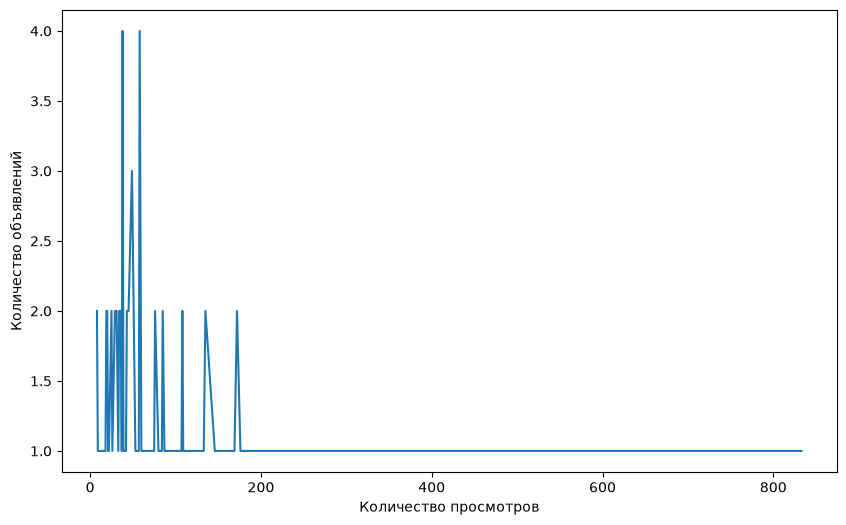

In [16]:
df_views_total = df['views_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_views_total.index, df_views_total.values)
plt.xlabel('Количество просмотров')
plt.ylabel('Количество объявлений')
plt.show()

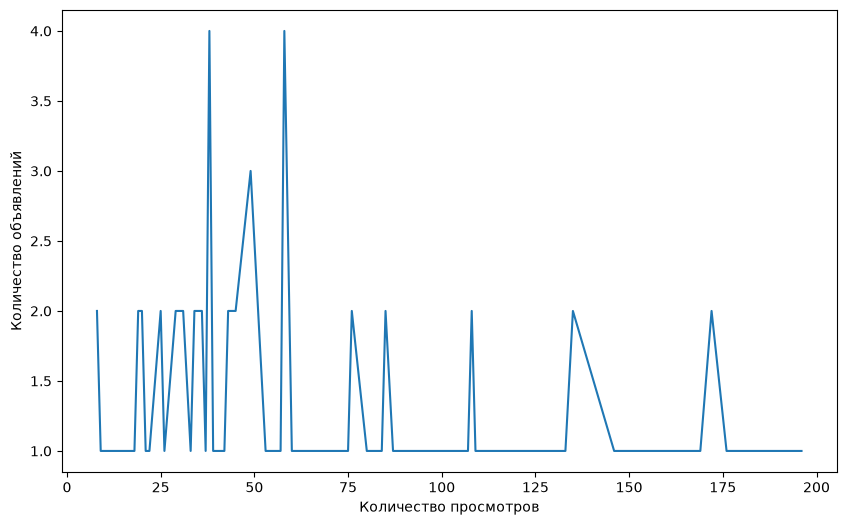

In [17]:
df_views_total_tmp = df_views_total[df_views_total.index < 200]
plt.figure(figsize=(10, 6))
plt.xlabel('Количество просмотров')
plt.ylabel('Количество объявлений')
plt.plot(df_views_total_tmp.index, df_views_total_tmp.values)
plt.show()

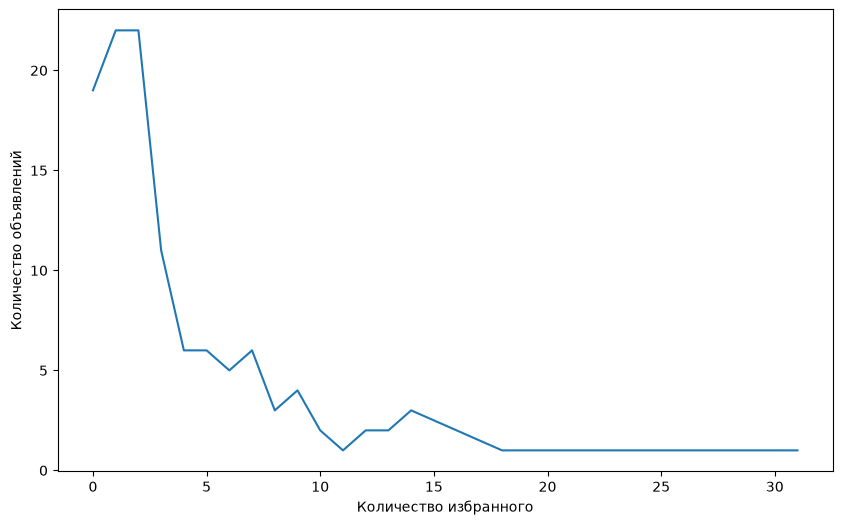

In [18]:
df_favorites_total = df['favorites_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_favorites_total.index, df_favorites_total.values)
plt.xlabel('Количество избранного')
plt.ylabel('Количество объявлений')
plt.show()

phone_views_total
0     47
1     28
2     20
3      9
4      5
5      2
6      1
7      2
8      1
12     1
Name: count, dtype: int64

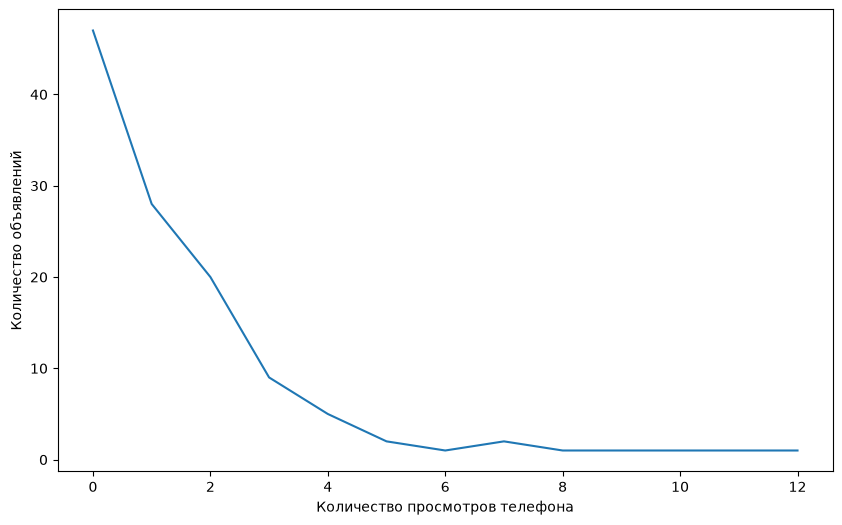

In [19]:
df_phone_views_total = df['phone_views_total'].value_counts().sort_index()
display(df_phone_views_total)
plt.figure(figsize=(10, 6))
plt.plot(df_phone_views_total.index, df_phone_views_total.values)
plt.xlabel('Количество просмотров телефона')
plt.ylabel('Количество объявлений')
plt.show()

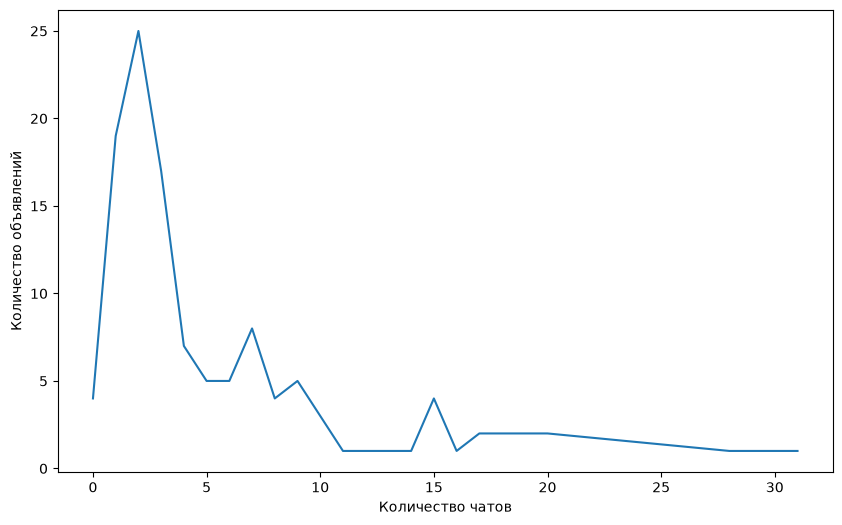

In [20]:
df_chats_total = df['chats_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_chats_total.index, df_chats_total.values)
plt.xlabel('Количество чатов')
plt.ylabel('Количество объявлений')
plt.show()

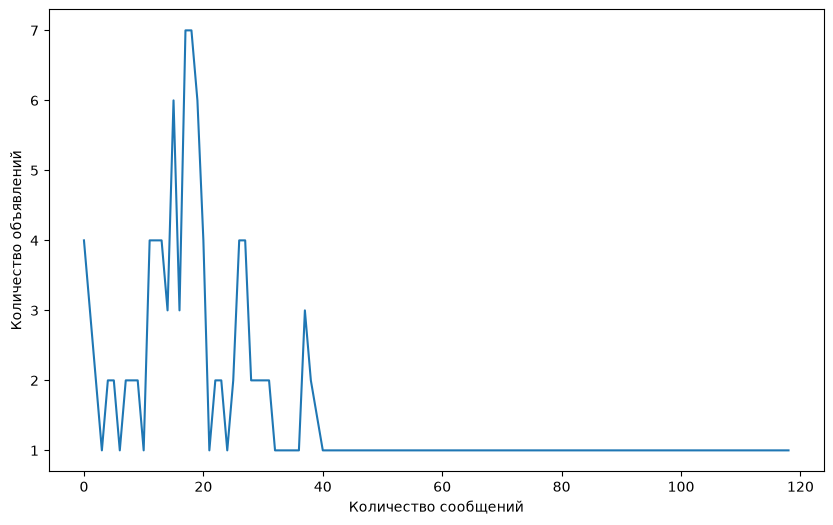

In [21]:
df_messages_total = df['messages_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_messages_total.index, df_messages_total.values)
plt.xlabel('Количество сообщений')
plt.ylabel('Количество объявлений')
plt.show()

## Анализ is_deal == 0

In [22]:
df = verified_listings_0.copy()

df_private = df[df['seller_type'] == 'private']
df_business = df[df['seller_type'] == 'business']

df_private

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
96,152219,38883,private,Спорт и отдых,Коньки отличное состояние,5260,5260,2,45.0,Краснодар,2026-09-27 18:03:35,2026-10-03 13:31:14,снято продавцом,36,0,0,3,6
162,133335,26727,private,Бытовая техника,Мультиварка торг,19120,19120,4,61.0,Москва,2026-09-09 08:22:14,2026-09-14 12:56:15,снято продавцом,60,3,0,1,13
242,115714,22840,private,Мебель и интерьер,Люстра,9300,7550,4,129.0,Москва,2026-08-19 21:24:55,2026-09-18 21:24:55,истёк срок,278,7,3,11,42
287,159583,19213,private,Электроника,Игровая приставка,14770,14770,2,NaN,Екатеринбург,2026-10-04 17:49:59,2026-10-18 20:38:31,снято продавцом,146,6,2,4,13
294,109228,18276,private,Детские товары,Комбинезон зимний,5250,3980,3,176.0,Москва,2026-08-12 15:53:29,2026-09-11 15:53:29,истёк срок,169,4,2,13,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15125,114464,12962,private,Электроника,iPhone 12 128 ГБ б/у,14470,14470,5,122.0,Краснодар,2026-08-18 15:28:05,2026-09-17 15:28:05,истёк срок,294,12,3,14,53
15148,125458,20955,private,Мебель и интерьер,Люстра,4110,4110,3,50.0,Москва,2026-08-31 20:19:52,2026-09-09 13:56:03,снято продавцом,53,2,0,2,5
15161,122935,21280,private,Одежда и обувь,Свитер вязаный в хорошем состоянии,2170,2170,4,100.0,Краснодар,2026-08-28 20:29:54,2026-08-31 12:09:28,снято продавцом,23,0,0,2,4
15187,122765,25599,private,Одежда и обувь,Платье вечернее,1270,1270,4,33.0,Москва,2026-08-28 18:09:45,2026-09-09 18:41:33,снято продавцом,55,1,1,4,7


In [23]:
df_business

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
1694,117901,19608,business,Одежда и обувь,Свитер вязаный отличное состояние,1580,1580,9,1087.0,Санкт-Петербург,2026-08-22 17:01:05,2026-09-21 17:01:05,истёк срок,240,7,1,19,61
2763,135886,13674,business,Электроника,Планшет Huawei MatePad,32580,32580,6,NaN,Новосибирск,2026-09-11 18:52:51,2026-10-11 18:52:51,истёк срок,645,21,2,28,97
3195,147955,17554,business,Спорт и отдых,Сноуборд с креплениями,6780,6780,3,381.0,Нижний Новгород,2026-09-23 15:47:11,2026-10-23 15:47:11,истёк срок,270,7,3,16,63
4023,156170,12907,business,Мебель и интерьер,Кресло офисное б/у,123456789,123456789,8,270.0,Екатеринбург,2026-10-01 16:19:50,2026-10-31 16:19:50,истёк срок,492,15,4,31,128
5461,145729,13634,business,Электроника,Электронная книга,11370,11370,9,217.0,Екатеринбург,2026-09-21 12:03:03,2026-10-21 12:03:03,истёк срок,550,20,5,30,127
6496,155586,10504,business,Детские товары,Велосипед детский торг,3810,3380,7,257.0,Екатеринбург,2026-09-30 21:40:18,2026-10-30 21:40:18,истёк срок,684,17,6,33,111
7049,151142,10157,business,Мебель и интерьер,Стеллаж,11920,11920,9,398.0,Краснодар,2026-09-26 17:05:08,2026-10-26 17:05:08,истёк срок,435,20,6,12,37
7743,161231,11774,business,Запчасти и аксессуары,Тормозные колодки б/у,3500,3500,7,448.0,Самара,2026-10-05 23:14:46,2026-11-04 23:14:46,истёк срок,345,10,11,8,40
8167,139526,13092,business,Детские товары,Велосипед детский новый,2550,2550,8,94.0,г. Казань,2026-09-15 09:13:27,2026-10-15 09:13:27,истёк срок,562,20,6,20,68
8657,132817,11107,business,Запчасти и аксессуары,Видеорегистратор в хорошем состоянии,11240,11240,5,119.0,Нижний Новгород,2026-09-08 15:23:57,2026-10-08 15:23:57,истёк срок,177,4,6,5,19


In [24]:
len(df_private), len(df_business)

(171, 13)

In [25]:
df_categories = df['category'].value_counts()
df_categories

category
Одежда и обувь           45
Электроника              33
Запчасти и аксессуары    24
Детские товары           22
Спорт и отдых            19
Мебель и интерьер        19
Бытовая техника          18
Name: count, dtype: int64

In [26]:
df_sorted_prices = df.sort_values(by='price', ascending=False)
df_sorted_prices

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
1664,158937,32792,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,123456789,123456789,3,53.0,Москва,2026-10-03 23:48:34,2026-10-06 08:18:40,снято продавцом,34,1,0,2,4
1799,118493,21680,private,Мебель и интерьер,Тумба под ТВ с документами,123456789,123456789,2,37.0,Москва,2026-08-23 12:39:22,2026-09-22 12:39:22,истёк срок,139,5,1,5,17
4023,156170,12907,business,Мебель и интерьер,Кресло офисное б/у,123456789,123456789,8,270.0,Екатеринбург,2026-10-01 16:19:50,2026-10-31 16:19:50,истёк срок,492,15,4,31,128
4718,130827,31231,private,Одежда и обувь,Свитер вязаный отличное состояние,99999999,99999999,3,80.0,Москва,2026-09-06 17:01:26,2026-09-08 19:01:00,снято продавцом,20,0,0,2,12
7945,147075,37350,private,Электроника,Ноутбук Lenovo IdeaPad б/у,74470,74470,6,196.0,Москва,2026-09-22 17:00:14,2026-09-27 20:08:02,снято продавцом,72,3,0,5,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,106328,15932,private,Одежда и обувь,Костюм мужской новый,740,740,3,61.0,Москва,2026-08-08 21:55:17,2026-08-13 14:16:35,снято продавцом,15,0,0,2,21
2344,119883,25617,private,Одежда и обувь,Кроссовки Nike отличное состояние,660,660,7,112.0,Москва,2026-08-24 21:45:33,2026-09-23 21:45:33,истёк срок,344,10,0,14,47
5171,116852,23587,private,Одежда и обувь,Пальто шерстяное б/у,600,600,4,53.0,Санкт-Петербург,2026-08-21 12:39:30,2026-08-24 04:53:50,заблокировано,28,0,1,2,7
3376,131050,31511,private,Одежда и обувь,Кроссовки Nike отличное состояние,550,550,2,51.0,Самара,2026-09-06 19:31:42,2026-10-06 19:31:42,истёк срок,309,19,0,13,67


In [27]:
df_sorted_prices = df_sorted_prices.drop(index=df_sorted_prices.index[0:4])
df_sorted_prices

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
7945,147075,37350,private,Электроника,Ноутбук Lenovo IdeaPad б/у,74470,74470,6,196.0,Москва,2026-09-22 17:00:14,2026-09-27 20:08:02,снято продавцом,72,3,0,5,18
2139,128614,30377,private,Электроника,Колонка JBL отличное состояние,43680,43680,6,212.0,Екатеринбург,2026-09-04 11:43:11,2026-09-10 20:23:12,снято продавцом,39,0,1,3,6
1001,119444,18397,private,Электроника,Колонка JBL как новый,39850,31430,6,339.0,Краснодар,2026-08-24 15:36:47,2026-09-23 15:36:47,истёк срок,458,15,5,15,72
12859,141557,26031,private,Электроника,Фотоаппарат Canon торг,34950,34950,3,63.0,Краснодар,2026-09-16 21:27:17,2026-09-18 21:08:00,снято продавцом,34,2,0,0,0
2763,135886,13674,business,Электроника,Планшет Huawei MatePad,32580,32580,6,NaN,Новосибирск,2026-09-11 18:52:51,2026-10-11 18:52:51,истёк срок,645,21,2,28,97
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,106328,15932,private,Одежда и обувь,Костюм мужской новый,740,740,3,61.0,Москва,2026-08-08 21:55:17,2026-08-13 14:16:35,снято продавцом,15,0,0,2,21
2344,119883,25617,private,Одежда и обувь,Кроссовки Nike отличное состояние,660,660,7,112.0,Москва,2026-08-24 21:45:33,2026-09-23 21:45:33,истёк срок,344,10,0,14,47
5171,116852,23587,private,Одежда и обувь,Пальто шерстяное б/у,600,600,4,53.0,Санкт-Петербург,2026-08-21 12:39:30,2026-08-24 04:53:50,заблокировано,28,0,1,2,7
3376,131050,31511,private,Одежда и обувь,Кроссовки Nike отличное состояние,550,550,2,51.0,Самара,2026-09-06 19:31:42,2026-10-06 19:31:42,истёк срок,309,19,0,13,67


In [28]:
df_chaged_price = df[df['price'] != df['current_price']]
df_chaged_price

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
242,115714,22840,private,Мебель и интерьер,Люстра,9300,7550,4,129.0,Москва,2026-08-19 21:24:55,2026-09-18 21:24:55,истёк срок,278,7,3,11,42
294,109228,18276,private,Детские товары,Комбинезон зимний,5250,3980,3,176.0,Москва,2026-08-12 15:53:29,2026-09-11 15:53:29,истёк срок,169,4,2,13,35
727,160017,15177,private,Одежда и обувь,Худи оверсайз б/у,1040,860,2,108.0,Екатеринбург,2026-10-04 21:46:08,2026-11-03 21:46:08,истёк срок,122,4,0,7,25
789,114122,21766,private,Мебель и интерьер,Стеллаж с документами,5670,5050,3,166.0,Краснодар,2026-08-17 22:17:42,2026-09-16 22:17:42,истёк срок,126,5,1,7,30
1001,119444,18397,private,Электроника,Колонка JBL как новый,39850,31430,6,339.0,Краснодар,2026-08-24 15:36:47,2026-09-23 15:36:47,истёк срок,458,15,5,15,72
1233,154476,39518,private,Бытовая техника,Кофемашина DeLonghi,5410,4540,3,163.0,Казань,2026-09-29 20:48:18,2026-10-29 20:48:18,истёк срок,335,18,8,8,45
1345,110348,19046,private,Запчасти и аксессуары,Тормозные колодки новый,2830,2550,2,24.0,Екатеринбург,2026-08-13 19:51:11,2026-08-22 19:03:19,снято продавцом,23,1,1,0,0
1943,115329,22603,private,Бытовая техника,Робот-пылесос,5650,5240,2,26.0,Москва,2026-08-19 16:10:13,2026-09-18 16:10:13,истёк срок,153,6,1,6,27
2658,116047,23101,private,Одежда и обувь,Куртка зимняя,1370,1210,2,100.0,Москва,2026-08-20 14:12:46,2026-09-19 14:12:46,истёк срок,66,4,0,1,3
2869,110120,18888,private,Спорт и отдых,Лыжи беговые б/у,4420,3480,3,176.0,г. Краснодар,2026-08-13 16:52:19,2026-09-12 16:52:19,истёк срок,140,5,1,4,20


In [29]:
len(df_chaged_price)

31

In [30]:
df_photos_count = df['photos_count'].value_counts().sort_index()
df_photos_count

photos_count
0      4
1     16
2     25
3     29
4     41
5     24
6     17
7     11
8      8
9      6
10     3
Name: count, dtype: int64

Забавно, что нормальное распределение по кол-ву фотографий. Но не 100% показатель

In [31]:
df_description_length = df['description_length'].value_counts().sort_index()
df_description_length

description_length
12.0      1
22.0      2
23.0      1
24.0      1
25.0      1
         ..
448.0     1
501.0     1
559.0     1
695.0     1
1087.0    1
Name: count, Length: 126, dtype: int64

In [32]:
df_delta_time = pd.to_timedelta(df['closed_at'].apply(lambda x: pd.to_datetime(x).timestamp()) - df['published_at'].apply(lambda x: pd.to_datetime(x).timestamp()), unit='s')
df_delta_time = df_delta_time.value_counts().sort_index()
df_delta_time

0 days 14:10:03      1
0 days 22:31:15      1
0 days 22:43:34      1
0 days 22:50:34      1
1 days 00:15:45      1
                    ..
16 days 05:12:18     1
18 days 01:37:14     1
18 days 05:04:20     1
18 days 08:18:35     1
30 days 00:00:00    79
Name: count, Length: 106, dtype: int64

30 дней - смерть обьявления

In [33]:
df_close_type = df['close_type'].value_counts()
df_close_type

close_type
снято продавцом    103
истёк срок          79
заблокировано        2
Name: count, dtype: int64

In [34]:
df_blocked = df[df['close_type'] == "заблокировано"]
df_blocked

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
5171,116852,23587,private,Одежда и обувь,Пальто шерстяное б/у,600,600,4,53.0,Санкт-Петербург,2026-08-21 12:39:30,2026-08-24 04:53:50,заблокировано,28,0,1,2,7
7275,133962,27148,private,Детские товары,Комбинезон зимний как новый,4050,3780,5,76.0,Самара,2026-09-09 20:29:21,2026-09-11 23:22:35,заблокировано,8,0,0,1,2


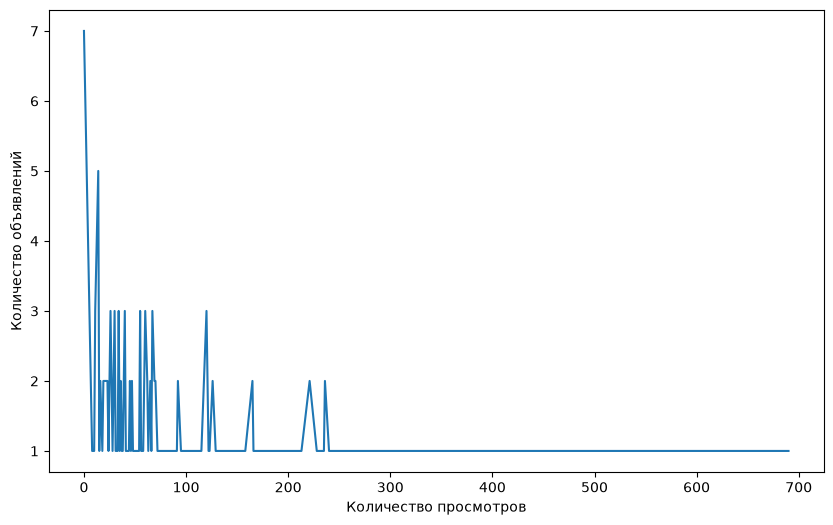

In [35]:
df_views_total = df['views_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_views_total.index, df_views_total.values)
plt.xlabel('Количество просмотров')
plt.ylabel('Количество объявлений')
plt.show()

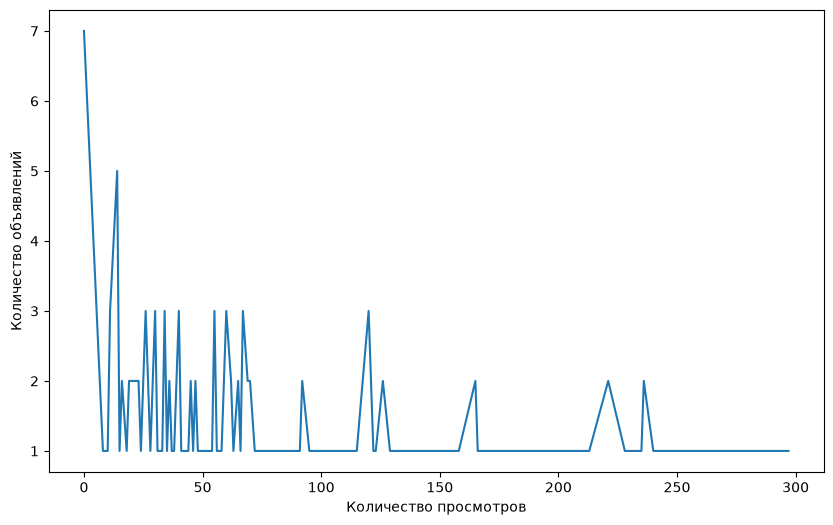

In [36]:
df_views_total_tmp = df_views_total[df_views_total.index < 300]
plt.figure(figsize=(10, 6))
plt.xlabel('Количество просмотров')
plt.ylabel('Количество объявлений')
plt.plot(df_views_total_tmp.index, df_views_total_tmp.values)
plt.show()

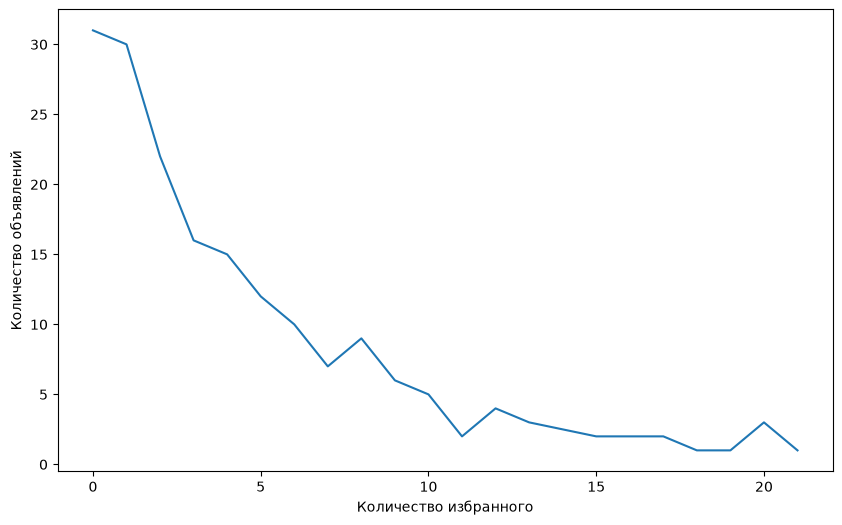

In [37]:
df_favorites_total = df['favorites_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_favorites_total.index, df_favorites_total.values)
plt.xlabel('Количество избранного')
plt.ylabel('Количество объявлений')
plt.show()

phone_views_total
0     78
1     43
2     21
3     18
4      6
5      6
6      6
8      3
9      2
11     1
Name: count, dtype: int64

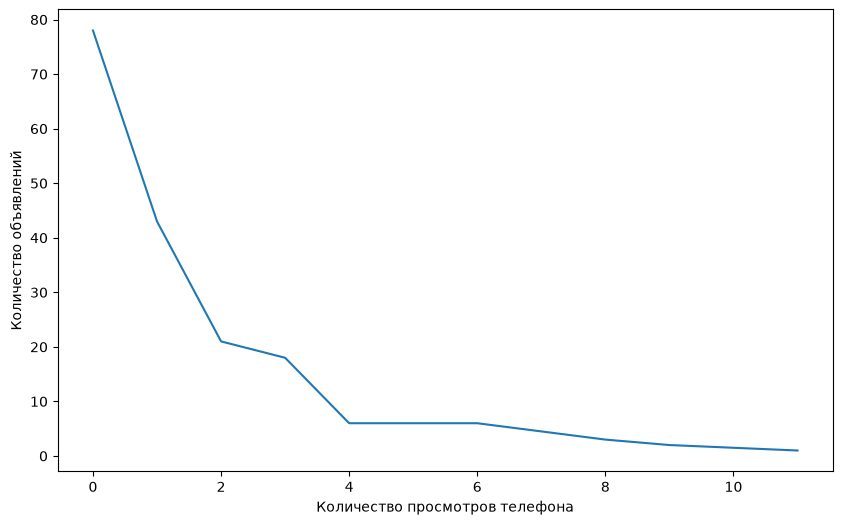

In [38]:
df_phone_views_total = df['phone_views_total'].value_counts().sort_index()
display(df_phone_views_total)
plt.figure(figsize=(10, 6))
plt.plot(df_phone_views_total.index, df_phone_views_total.values)
plt.xlabel('Количество просмотров телефона')
plt.ylabel('Количество объявлений')
plt.show()

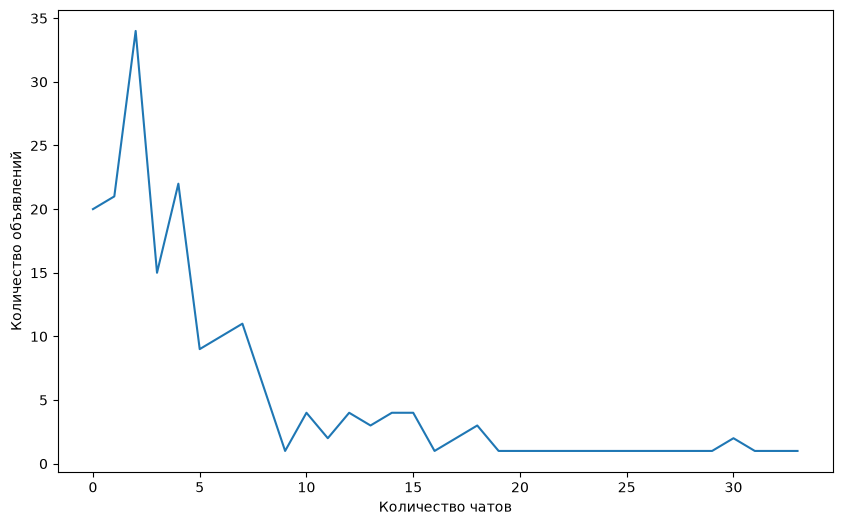

In [39]:
df_chats_total = df['chats_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_chats_total.index, df_chats_total.values)
plt.xlabel('Количество чатов')
plt.ylabel('Количество объявлений')
plt.show()

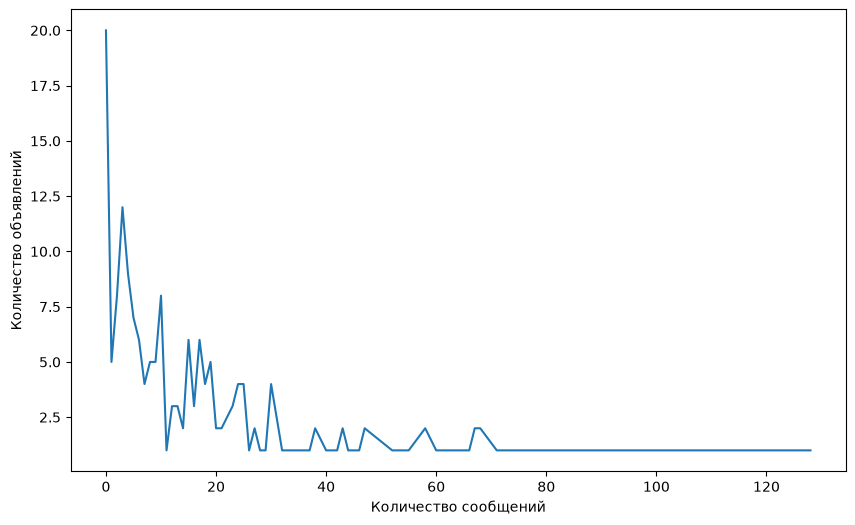

In [40]:
df_messages_total = df['messages_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_messages_total.index, df_messages_total.values)
plt.xlabel('Количество сообщений')
plt.ylabel('Количество объявлений')
plt.show()